In [100]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [101]:
pd.set_option('display.max_columns', None)

In [102]:
from pathlib import Path

# Resolve the dataset from the project root so the notebook works from any cwd.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'Notebooks' else Path.cwd()
DATA_PATH = PROJECT_ROOT / 'data' / 'Cleaned' / 'property_v2.csv'

df = pd.read_csv(DATA_PATH).drop_duplicates()

In [103]:
df.head()

,property_type,society,price,price_per_sqft,sector,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,Pooja Room,Study Room,Store Room,Servant Room,Others,furnishstatus,luxury_score,super_built_up_area,built_up_area,carpet_area
0,flat,indiabulls centrum park,2.45,NaN,sector 103,2875.25,Super Built up area 2875(267.1 sq.m.),4,4,3.0,11.0,East,Medium Aged,1,1,1,1,0,0,38,2875.0,NaN,NaN
1,house,project mianwali colony,2.00,14815.0,mianwali colony,1350.00,Built Up area: 1350 (125.42 sq.m.),5,5,2.0,3.0,East,Undefined,0,0,0,0,0,0,0,NaN,1350.0,NaN
2,flat,paras dews,1.50,NaN,sector 106,2355.16,Super Built up area 2355(218.79 sq.m.)Built Up...,4,6,3.0,11.0,North-West,Medium Aged,0,0,0,1,0,0,174,2355.0,1535.0,1403.000000
3,flat,rof ananda,0.38,NaN,sector 95,549.21,Carpet area: 549.17 (51.02 sq.m.),2,2,1.0,4.0,NaN,New,0,0,0,0,0,1,0,NaN,NaN,549.174178
4,flat,sare homes,0.68,NaN,sector 92,1298.21,Carpet area: 1298 (120.59 sq.m.),3,3,2.0,11.0,North-West,Medium Aged,1,0,0,0,0,1,100,NaN,NaN,1298.000000


In [104]:
df.shape

(3777, 23)

In [105]:
df.columns

Index(['property_type', 'society', 'price', 'price_per_sqft', 'sector', 'area',
       'areaWithType', 'bedRoom', 'bathroom', 'balcony', 'floorNum', 'facing',
       'agePossession', 'Pooja Room', 'Study Room', 'Store Room',
       'Servant Room', 'Others', 'furnishstatus', 'luxury_score',
       'super_built_up_area', 'built_up_area', 'carpet_area'],
      dtype='object')

/var/folders/b_/s74htpc90ps4hdvn1vgvtjgr0000gn/T/ipykernel_2070/2797181776.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['price'])


<Axes: xlabel='price', ylabel='Density'>

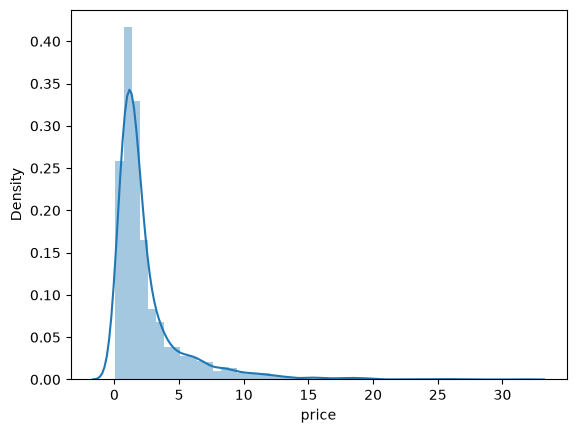

In [106]:
# outliers on the basis of price column
sns.distplot(df['price'])

<Axes: xlabel='price'>

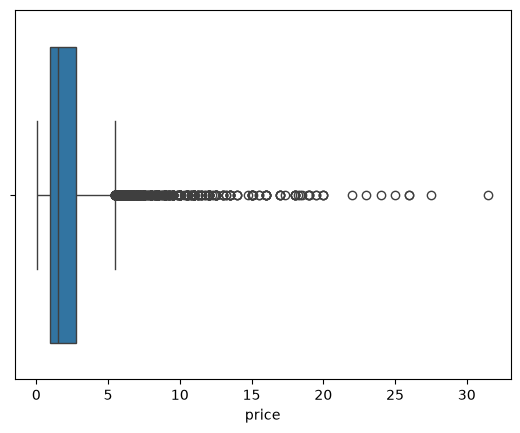

In [107]:
sns.boxplot(x=df['price'])

In [108]:
df.shape

(3777, 23)

In [109]:
# Calculate the IQR for the 'price' column
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

# Define bounds for outliers
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify outliers
outliers = df[(df['price'] < lower_bound) | (df['price'] > upper_bound)]

# Displaying the number of outliers and some statistics
num_outliers = outliers.shape[0]
outliers_price_stats = outliers['price'].describe()

num_outliers, outliers_price_stats

(433,
 count    433.000000
 mean       9.213603
 std        4.055215
 min        5.500000
 25%        6.440000
 50%        8.000000
 75%       10.560000
 max       31.500000
 Name: price, dtype: float64)

In [110]:
outliers.sort_values('price',ascending=False).head(20)

,property_type,society,price,price_per_sqft,sector,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,Pooja Room,Study Room,Store Room,Servant Room,Others,furnishstatus,luxury_score,super_built_up_area,built_up_area,carpet_area
2041,house,arjun marg/ sector- 26 phase- 1/ golf course road,31.50,35000.0,dlf phase 1,9000.0,Plot area 1000(836.13 sq.m.),7,9,3.0,3.0,North-East,Old,1,1,1,1,0,1,74,NaN,1000.0,NaN
3695,house,independent,27.50,24366.0,sushant lok phase 1,11286.0,Plot area 1254(1048.5 sq.m.),6,7,3.0,3.0,North-East,Medium Aged,1,1,0,1,1,2,42,NaN,1254.0,NaN
346,house,dlf city plots,26.00,57206.0,dlf phase 1,4545.0,Plot area 505(422.24 sq.m.),6,7,3.0,2.0,North-East,New,1,1,0,1,1,2,138,NaN,505.0,NaN
1367,house,independent,26.00,82540.0,dlf phase 1,3150.0,Plot area 402(336.12 sq.m.)Built Up area: 400 ...,16,16,3.0,4.0,North-West,New,1,1,1,1,0,2,72,NaN,400.0,350.0
1982,house,suncity township,25.00,31111.0,sector 54,8036.0,Plot area 1000(836.13 sq.m.),4,4,3.0,2.0,North,Old,1,1,1,1,0,1,0,NaN,1000.0,NaN
2294,house,emaar the palm springs,24.00,600000.0,sector 54,400.0,Plot area 400(37.16 sq.m.),5,5,2.0,1.0,North-East,Very Old,1,1,0,1,0,2,122,NaN,400.0,NaN
3030,house,independent,23.00,25556.0,dlf phase 1,9000.0,Plot area 1000(836.13 sq.m.),4,4,3.0,2.0,South-West,Medium Aged,1,1,1,1,0,2,145,NaN,1000.0,NaN
484,house,vipul tatvam villa,22.00,26667.0,sector 48,8250.0,Plot area 1000(836.13 sq.m.),5,6,3.0,3.0,NaN,Old,0,0,0,1,0,0,54,NaN,1000.0,NaN
2102,house,dlf city plots,20.00,44265.0,dlf phase 1,4518.0,Plot area 502(419.74 sq.m.),16,20,3.0,4.0,North-East,Under Construction,1,1,1,1,0,2,153,NaN,502.0,NaN
1202,house,luxury dlf city floors,20.00,48889.0,dlf phase 1,4091.0,Plot area 500(418.06 sq.m.),16,16,3.0,4.0,NaN,New,0,0,0,1,0,2,31,NaN,500.0,NaN


In [111]:
# on the basis of price col we can say that there are some genuine outliers but there are some data erros as well
df.shape

(3777, 23)

### Price_per_sqft

/var/folders/b_/s74htpc90ps4hdvn1vgvtjgr0000gn/T/ipykernel_2070/2186227091.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['price_per_sqft'])


<Axes: xlabel='price_per_sqft', ylabel='Density'>

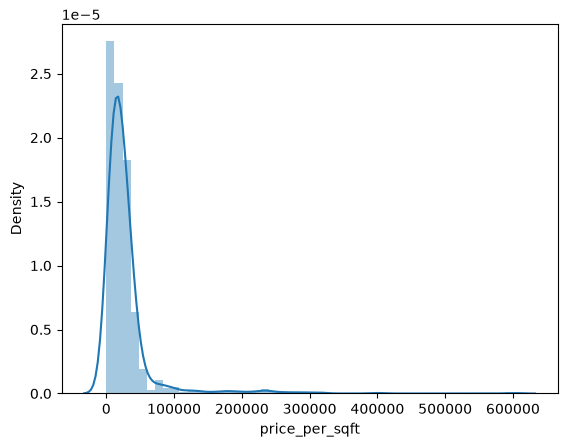

In [112]:
sns.distplot(df['price_per_sqft'])

<Axes: xlabel='price_per_sqft'>

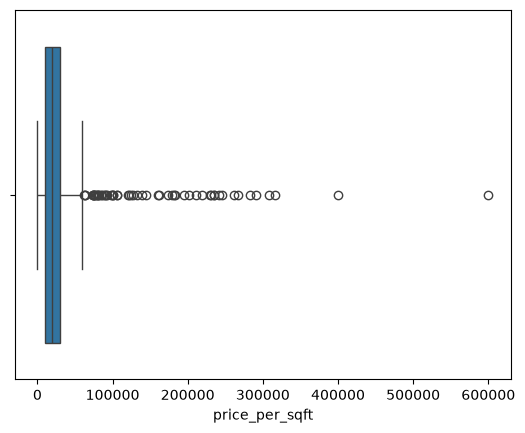

In [113]:
sns.boxplot(x=df['price_per_sqft'])

In [114]:
# Calculate the IQR for the 'price' column
Q1 = df['price_per_sqft'].quantile(0.25)
Q3 = df['price_per_sqft'].quantile(0.75)
IQR = Q3 - Q1

# Define bounds for outliers
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify outliers
outliers_sqft = df[(df['price_per_sqft'] < lower_bound) | (df['price_per_sqft'] > upper_bound)]

# Displaying the number of outliers and some statistics
num_outliers = outliers_sqft.shape[0]
outliers_sqft_stats = outliers_sqft['price_per_sqft'].describe()

num_outliers, outliers_sqft_stats

(57,
 count        57.000000
 mean     159600.298246
 std       99897.787167
 min       62222.000000
 25%       84000.000000
 50%      125000.000000
 75%      218750.000000
 max      600000.000000
 Name: price_per_sqft, dtype: float64)

In [115]:
outliers_sqft['area'] = outliers_sqft['area'].apply(lambda x:x*9 if x<1000 else x)

/var/folders/b_/s74htpc90ps4hdvn1vgvtjgr0000gn/T/ipykernel_2070/205471443.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  outliers_sqft['area'] = outliers_sqft['area'].apply(lambda x:x*9 if x<1000 else x)


In [116]:
outliers_sqft['price_per_sqft'] = round((outliers_sqft['price']*10000000)/outliers_sqft['area'])

/var/folders/b_/s74htpc90ps4hdvn1vgvtjgr0000gn/T/ipykernel_2070/3686006548.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  outliers_sqft['price_per_sqft'] = round((outliers_sqft['price']*10000000)/outliers_sqft['area'])


In [117]:
outliers_sqft['price_per_sqft'].describe()

count       57.000000
mean     20980.789474
std      15961.035903
min       7062.000000
25%      10000.000000
50%      15432.000000
75%      26042.000000
max      82540.000000
Name: price_per_sqft, dtype: float64

In [118]:
df.update(outliers_sqft)
df.shape

(3777, 23)

/var/folders/b_/s74htpc90ps4hdvn1vgvtjgr0000gn/T/ipykernel_2070/2186227091.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['price_per_sqft'])


<Axes: xlabel='price_per_sqft', ylabel='Density'>

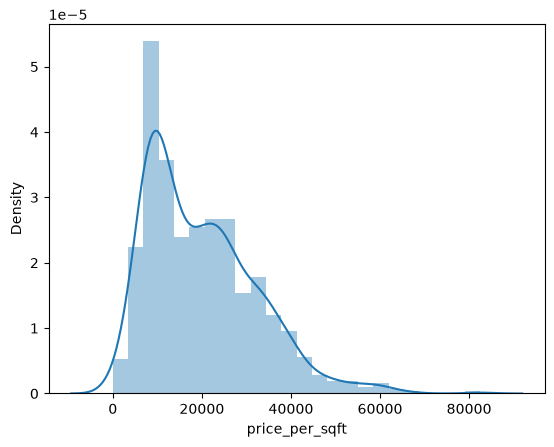

In [119]:
sns.distplot(df['price_per_sqft'])

<Axes: xlabel='price_per_sqft'>

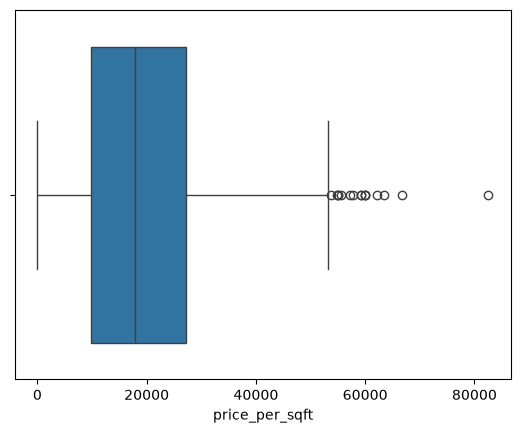

In [120]:
sns.boxplot(x=df['price_per_sqft'])

In [121]:
df.shape

(3777, 23)

In [122]:
df[df['price_per_sqft']>=50000].shape

(22, 23)

In [123]:
df[df['price_per_sqft'] <= 50000].shape


(926, 23)

<Axes: xlabel='price_per_sqft'>

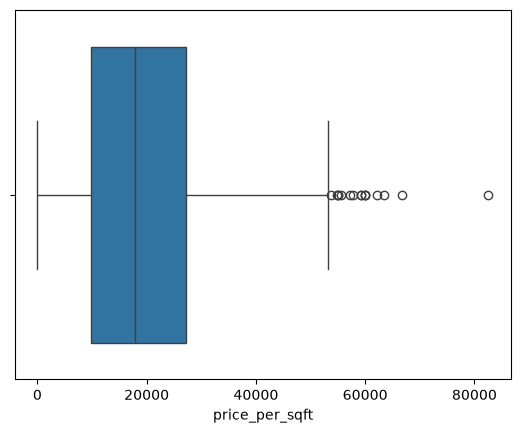

In [124]:
sns.boxplot(x=df['price_per_sqft'])

In [125]:
df.shape

(3777, 23)

### Area

/var/folders/b_/s74htpc90ps4hdvn1vgvtjgr0000gn/T/ipykernel_2070/91062565.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['area'])


<Axes: xlabel='area', ylabel='Density'>

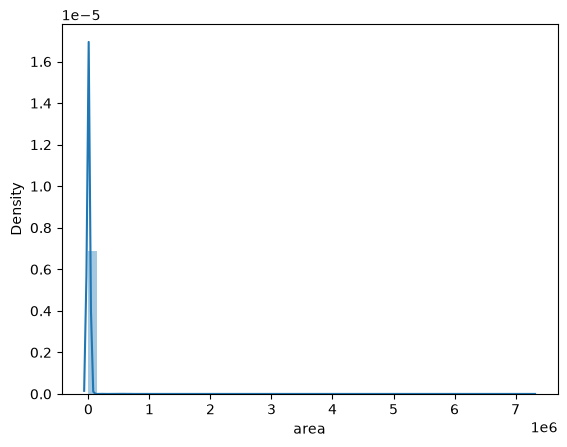

In [126]:
sns.distplot(df['area'])

<Axes: xlabel='area'>

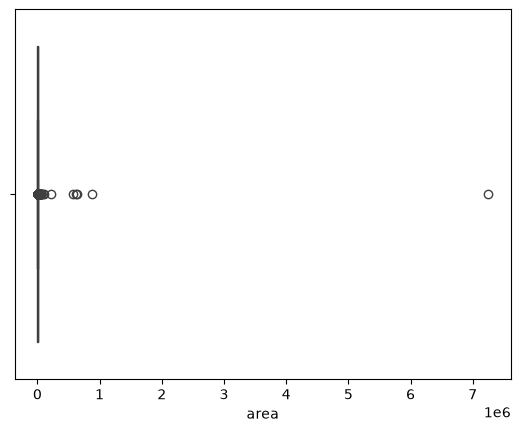

In [127]:
sns.boxplot(x=df['area'])

In [128]:
df['area'].describe()

count    3.749000e+03
mean     4.828885e+03
std      1.205569e+05
min      5.000000e+01
25%      1.230000e+03
50%      1.734100e+03
75%      2.310340e+03
max      7.250000e+06
Name: area, dtype: float64

In [129]:
df[df['area'] > 100000]

,property_type,society,price,price_per_sqft,sector,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,Pooja Room,Study Room,Store Room,Servant Room,Others,furnishstatus,luxury_score,super_built_up_area,built_up_area,carpet_area
1522,flat,ramsons kshitij,0.31,NaN,sector 95,620000.00,Carpet area: 607936 (56479.1 sq.m.),2,2,1.0,1.0,North-East,Medium Aged,0,1,0,0,1,1,65,NaN,NaN,607936.0
2177,flat,signature global solera,0.51,NaN,sector 107,566666.67,Carpet area: 514396 (47788.95 sq.m.),2,2,1.0,3.0,North,New,0,0,0,0,0,1,44,NaN,NaN,514396.0
2537,flat,signature the roselia,0.45,NaN,sector 95,642857.14,Carpet area: 569243 (52884.41 sq.m.),2,2,2.0,2.0,South-West,New,0,0,0,0,0,1,76,NaN,NaN,569243.0
2813,flat,hcbs sports ville,0.35,NaN,sohna road,875000.00,Built Up area: 737147 (68483.2 sq.m.),2,2,2.0,8.0,NaN,Medium Aged,0,0,0,0,0,1,44,NaN,737147.0,NaN
3176,house,independent,1.45,2.0,pataudi road,7250000.00,Plot area 200(809372 sq.m.),4,3,3.0,3.0,South,Old,0,0,0,0,0,1,0,NaN,200.0,NaN
3662,house,independent,5.00,232.0,sector 50,215517.00,Plot area 2(1011.71 sq.m.),6,5,3.0,2.0,NaN,New,1,1,0,1,1,2,0,NaN,2.0,NaN


In [130]:
df = df[df['area'] < 100000]

/var/folders/b_/s74htpc90ps4hdvn1vgvtjgr0000gn/T/ipykernel_2070/91062565.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['area'])


<Axes: xlabel='area', ylabel='Density'>

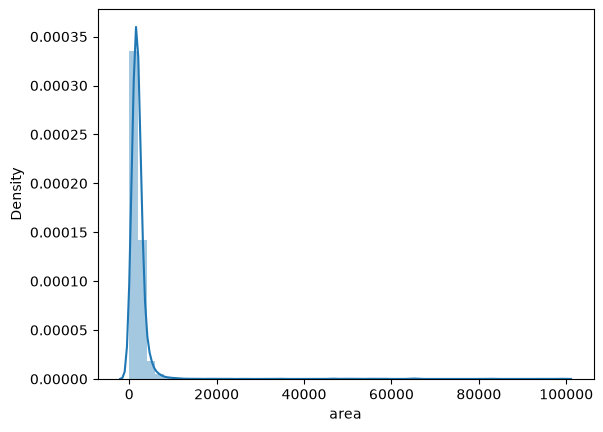

In [131]:
sns.distplot(df['area'])

<Axes: xlabel='area'>

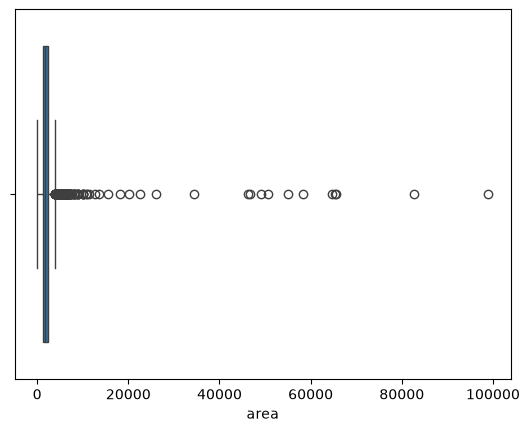

In [132]:
sns.boxplot(x=df['area'])

In [133]:
df[df['area'] > 10000].sort_values('area',ascending=False)

# 818, 1796, 1123, 2, 2356, 115, 3649, 2503, 1471

,property_type,society,price,price_per_sqft,sector,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,Pooja Room,Study Room,Store Room,Servant Room,Others,furnishstatus,luxury_score,super_built_up_area,built_up_area,carpet_area
267,house,independent,18.400,1859.0,dlf phase 1,98978.00,Plot area 502(419.74 sq.m.)Carpet area: 11000 ...,6,8,3.0,4.0,South,Medium Aged,1,0,1,1,0,2,60,NaN,NaN,11000.00
1735,house,ganpati heights apartment,1.250,151.0,prem nagar,82781.00,Plot area 115(7692.86 sq.m.),10,6,2.0,3.0,South-East,Very Old,0,0,0,0,1,0,7,NaN,115.0,NaN
3679,flat,rof ananda,0.380,NaN,sector 95,65517.24,Carpet area: 64412 (5984.07 sq.m.),3,2,1.0,12.0,North,Medium Aged,0,0,0,0,0,1,51,NaN,NaN,64412.00
2351,house,dlf city plot phase 4,13.000,1992.0,dlf phase 4,65261.00,Carpet area: 7250 (6061.92 sq.m.),10,10,3.0,1.0,NaN,Undefined,0,0,0,0,0,0,0,NaN,NaN,7250.00
1972,flat,rof ananda,0.375,NaN,sector 95,64655.17,Carpet area: 64529 (5994.94 sq.m.),2,2,2.0,10.0,East,New,0,1,0,0,0,1,15,NaN,NaN,64529.00
2391,flat,pyramid elite,0.460,NaN,sector 86,58227.85,Carpet area: 58141 (5401.48 sq.m.),2,2,1.0,0.0,NaN,Under Construction,0,0,0,0,0,1,15,NaN,NaN,58141.00
1377,flat,rof ananda,0.330,NaN,sector 95,55000.00,Carpet area: 54917 (5101.96 sq.m.),2,2,1.0,13.0,South-West,Medium Aged,0,0,0,0,0,1,37,NaN,NaN,54917.00
3190,house,independent,5.500,1087.0,mayfield garden,50598.00,Plot area 5620(4699.04 sq.m.)Built Up area: 82...,8,8,2.0,3.0,North-East,Medium Aged,1,0,0,0,0,2,49,NaN,8260.0,4860.00
2770,flat,signature the serenas,0.280,NaN,sohna road,49122.81,Carpet area: 48811 (4534.69 sq.m.),1,1,2.0,1.0,North-West,Medium Aged,0,1,0,0,0,1,37,NaN,NaN,48811.00
1012,house,independent,7.300,1560.0,dlf phase 2,46795.00,Plot area 215(179.77 sq.m.)Built Up area: 5800...,9,9,2.0,3.0,North-West,Medium Aged,0,0,1,1,0,0,109,NaN,5800.0,5200.00


In [134]:
# Some labels may already be gone after the previous area filter.
# Intersect with the current index to avoid KeyError when re-running cells.
invalid_area_rows = [818, 1796, 1123, 2, 2356, 115, 3649, 2503, 1471]
df.drop(index=df.index.intersection(invalid_area_rows), inplace=True)

In [135]:
df[df['area'] > 10000].sort_values('area',ascending=False)

,property_type,society,price,price_per_sqft,sector,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,Pooja Room,Study Room,Store Room,Servant Room,Others,furnishstatus,luxury_score,super_built_up_area,built_up_area,carpet_area
267,house,independent,18.400,1859.0,dlf phase 1,98978.00,Plot area 502(419.74 sq.m.)Carpet area: 11000 ...,6,8,3.0,4.0,South,Medium Aged,1,0,1,1,0,2,60,NaN,NaN,11000.00
1735,house,ganpati heights apartment,1.250,151.0,prem nagar,82781.00,Plot area 115(7692.86 sq.m.),10,6,2.0,3.0,South-East,Very Old,0,0,0,0,1,0,7,NaN,115.0,NaN
3679,flat,rof ananda,0.380,NaN,sector 95,65517.24,Carpet area: 64412 (5984.07 sq.m.),3,2,1.0,12.0,North,Medium Aged,0,0,0,0,0,1,51,NaN,NaN,64412.00
2351,house,dlf city plot phase 4,13.000,1992.0,dlf phase 4,65261.00,Carpet area: 7250 (6061.92 sq.m.),10,10,3.0,1.0,NaN,Undefined,0,0,0,0,0,0,0,NaN,NaN,7250.00
1972,flat,rof ananda,0.375,NaN,sector 95,64655.17,Carpet area: 64529 (5994.94 sq.m.),2,2,2.0,10.0,East,New,0,1,0,0,0,1,15,NaN,NaN,64529.00
2391,flat,pyramid elite,0.460,NaN,sector 86,58227.85,Carpet area: 58141 (5401.48 sq.m.),2,2,1.0,0.0,NaN,Under Construction,0,0,0,0,0,1,15,NaN,NaN,58141.00
1377,flat,rof ananda,0.330,NaN,sector 95,55000.00,Carpet area: 54917 (5101.96 sq.m.),2,2,1.0,13.0,South-West,Medium Aged,0,0,0,0,0,1,37,NaN,NaN,54917.00
3190,house,independent,5.500,1087.0,mayfield garden,50598.00,Plot area 5620(4699.04 sq.m.)Built Up area: 82...,8,8,2.0,3.0,North-East,Medium Aged,1,0,0,0,0,2,49,NaN,8260.0,4860.00
2770,flat,signature the serenas,0.280,NaN,sohna road,49122.81,Carpet area: 48811 (4534.69 sq.m.),1,1,2.0,1.0,North-West,Medium Aged,0,1,0,0,0,1,37,NaN,NaN,48811.00
1012,house,independent,7.300,1560.0,dlf phase 2,46795.00,Plot area 215(179.77 sq.m.)Built Up area: 5800...,9,9,2.0,3.0,North-West,Medium Aged,0,0,1,1,0,0,109,NaN,5800.0,5200.00


In [136]:
df.loc[48,'area'] = 115*9
df.loc[300,'area'] = 7250
df.loc[2666,'area'] = 5800
df.loc[1358,'area'] = 2660
df.loc[3195,'area'] = 2850
df.loc[2131,'area'] = 1812
df.loc[3088,'area'] = 2160
df.loc[3444,'area'] = 1175

/var/folders/b_/s74htpc90ps4hdvn1vgvtjgr0000gn/T/ipykernel_2070/91062565.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['area'])


<Axes: xlabel='area', ylabel='Density'>

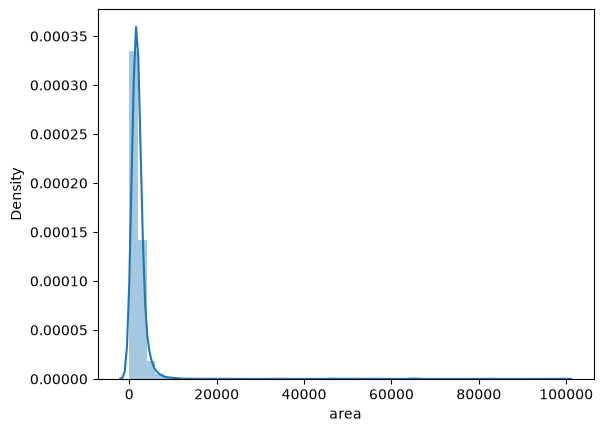

In [137]:
sns.distplot(df['area'])

<Axes: xlabel='area'>

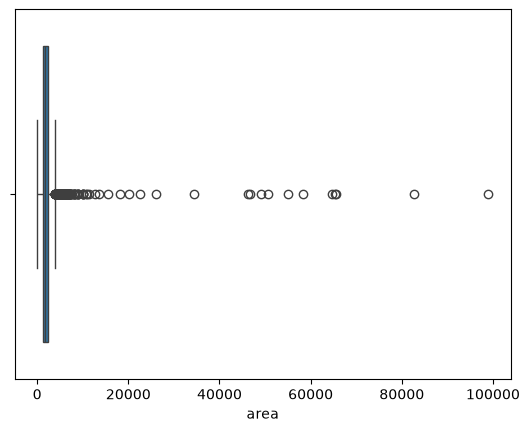

In [138]:
sns.boxplot(x=df['area'])

In [139]:
df['area'].describe()

count     3734.000000
mean      2120.936958
std       3682.010248
min         50.000000
25%       1225.075000
50%       1730.185000
75%       2300.322500
max      98978.000000
Name: area, dtype: float64

### Bedroom

/var/folders/b_/s74htpc90ps4hdvn1vgvtjgr0000gn/T/ipykernel_2070/1691983684.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['bedRoom'])


<Axes: xlabel='bedRoom', ylabel='Density'>

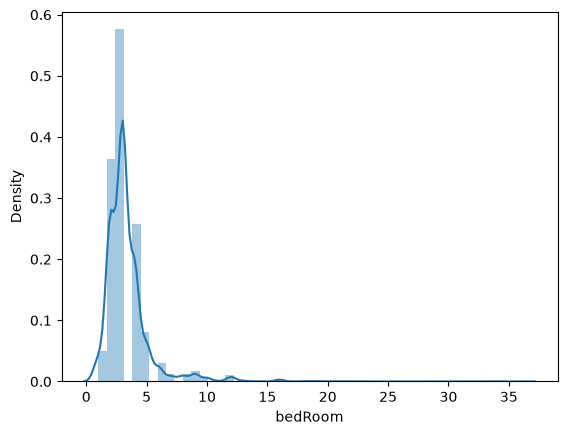

In [140]:
sns.distplot(df['bedRoom'])

<Axes: xlabel='bedRoom'>

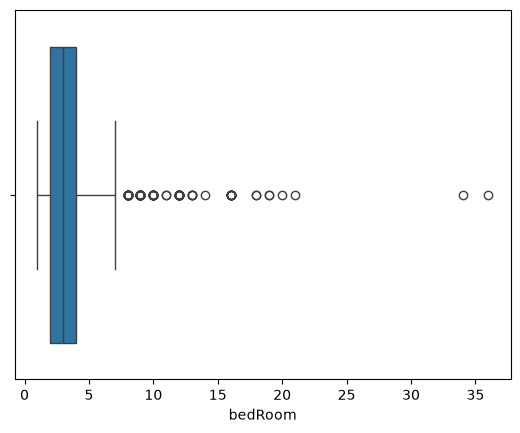

In [141]:
sns.boxplot(x=df['bedRoom'])

In [142]:
df['bedRoom'].describe()

count    3734.000000
mean        3.385645
std         2.031013
min         1.000000
25%         2.000000
50%         3.000000
75%         4.000000
max        36.000000
Name: bedRoom, dtype: float64

In [143]:
df[df['bedRoom'] > 10].sort_values('bedRoom',ascending=False)

,property_type,society,price,price_per_sqft,sector,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,Pooja Room,Study Room,Store Room,Servant Room,Others,furnishstatus,luxury_score,super_built_up_area,built_up_area,carpet_area
241,house,independent,2.25,6944.0,west rajiv nagar,3240.0,Plot area 360(301.01 sq.m.),36,36,2.0,3.0,East,Old,0,0,0,1,0,1,7,NaN,360.0,NaN
3189,house,manohar nagar,5.60,12444.0,manohar nagar,4500.0,Plot area 500(418.06 sq.m.)Built Up area: 500 ...,34,34,3.0,4.0,NaN,New,0,0,0,0,0,0,0,NaN,500.0,NaN
646,house,independent,5.00,43066.0,sector 54,1161.0,Plot area 129(107.86 sq.m.),21,21,3.0,5.0,North,Medium Aged,0,0,0,1,0,1,49,NaN,129.0,NaN
2281,house,independent,4.50,39062.0,sushant lok phase 1,1152.0,Plot area 128(107.02 sq.m.),20,20,3.0,4.0,East,Medium Aged,0,0,0,1,0,1,22,NaN,128.0,NaN
892,house,independent,3.93,24214.0,sector 17a,1623.0,Plot area 1623(150.78 sq.m.)Built Up area: 162...,19,17,3.0,4.0,North-West,Medium Aged,1,1,1,1,0,1,74,NaN,1622.0,NaN
1143,house,independent,3.87,5160.0,sector 17a,7500.0,Plot area 1623(150.78 sq.m.)Built Up area: 750...,19,17,3.0,5.0,North-West,Medium Aged,0,1,1,0,0,1,68,NaN,7500.0,NaN
1597,house,private house,7.05,46906.0,sector 55,1503.0,Plot area 167(139.63 sq.m.),18,18,3.0,4.0,North-East,Medium Aged,0,0,0,0,1,2,57,NaN,167.0,NaN
3198,house,independent,5.50,38194.0,suncity,1440.0,Plot area 160(133.78 sq.m.),18,18,3.0,4.0,South-West,Medium Aged,0,0,0,1,0,1,70,NaN,160.0,NaN
2102,house,dlf city plots,20.00,44265.0,dlf phase 1,4518.0,Plot area 502(419.74 sq.m.),16,20,3.0,4.0,North-East,Under Construction,1,1,1,1,0,2,153,NaN,502.0,NaN
1984,house,nul,12.50,51440.0,dlf phase 4,2430.0,Plot area 270(225.75 sq.m.),16,17,3.0,4.0,South,Medium Aged,1,1,0,1,1,2,137,NaN,270.0,NaN


In [144]:
df = df[df['bedRoom'] <= 10]

In [145]:
df.shape

(3681, 23)

/var/folders/b_/s74htpc90ps4hdvn1vgvtjgr0000gn/T/ipykernel_2070/1691983684.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['bedRoom'])


<Axes: xlabel='bedRoom', ylabel='Density'>

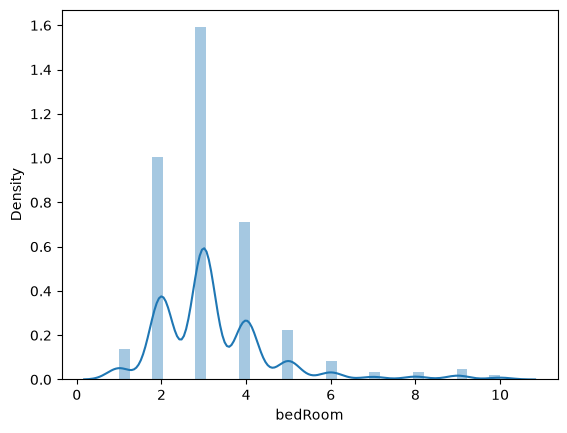

In [146]:
sns.distplot(df['bedRoom'])

<Axes: xlabel='bedRoom'>

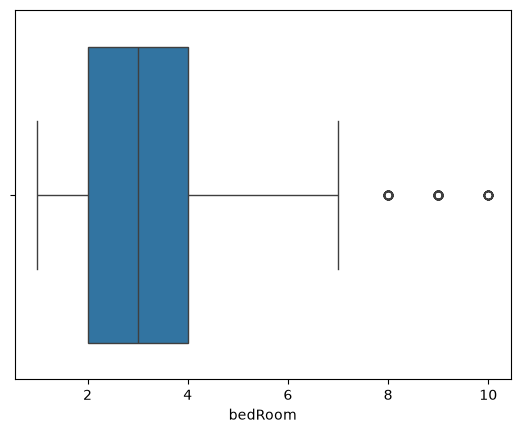

In [147]:
sns.boxplot(x=df['bedRoom'])

In [148]:
df['bedRoom'].describe()

count    3681.000000
mean        3.224396
std         1.422705
min         1.000000
25%         2.000000
50%         3.000000
75%         4.000000
max        10.000000
Name: bedRoom, dtype: float64

### Bathroom

/var/folders/b_/s74htpc90ps4hdvn1vgvtjgr0000gn/T/ipykernel_2070/2904465235.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['bathroom'])


<Axes: xlabel='bathroom', ylabel='Density'>

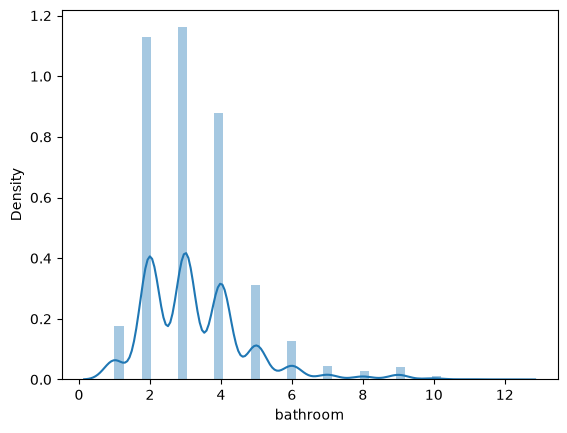

In [149]:
sns.distplot(df['bathroom'])

<Axes: xlabel='bathroom'>

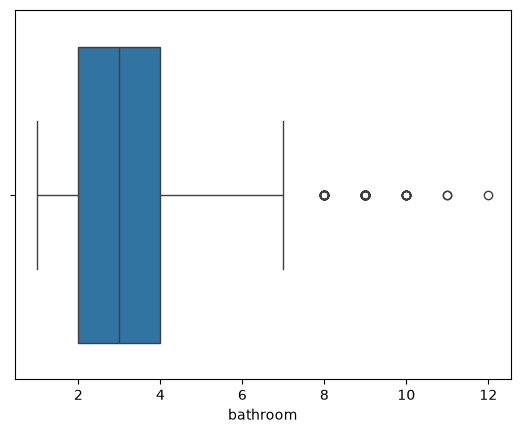

In [150]:
sns.boxplot(x=df['bathroom'])

In [151]:
df[df['bathroom'] > 10].sort_values('bathroom',ascending=False)

,property_type,society,price,price_per_sqft,sector,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,Pooja Room,Study Room,Store Room,Servant Room,Others,furnishstatus,luxury_score,super_built_up_area,built_up_area,carpet_area
2563,house,adani brahma samsara,18.02,28200.0,sector 60,6390.0,Built Up area: 6390 (593.65 sq.m.),9,12,3.0,3.0,North-East,Medium Aged,0,0,0,1,0,2,146,NaN,6390.0,NaN
2406,house,independent,7.00,10000.0,sector 39,7000.0,Plot area 350(32.52 sq.m.)Built Up area: 7000 ...,10,11,3.0,4.0,South-East,Medium Aged,1,0,0,0,0,2,38,NaN,7000.0,NaN
3237,house,independent,11.00,28898.0,dlf phase 3,3806.0,Plot area 3806.45(353.63 sq.m.)Built Up area: ...,8,11,3.0,3.0,East,Very Old,1,1,0,1,1,2,39,NaN,5000.0,NaN


### super built up area

<Axes: xlabel='super_built_up_area', ylabel='Count'>

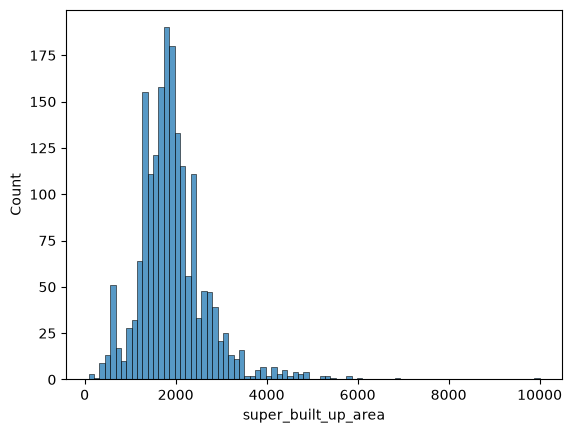

In [152]:
sns.histplot(df['super_built_up_area'])

<Axes: xlabel='super_built_up_area'>

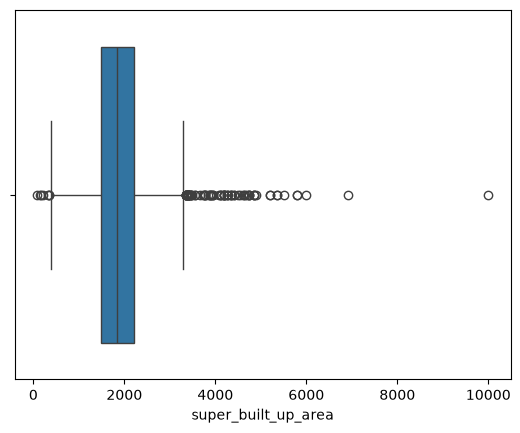

In [153]:
sns.boxplot(x=df['super_built_up_area'])

In [154]:
df['super_built_up_area'].describe()

count     1867.000000
mean      1926.921559
std        763.848041
min         89.000000
25%       1480.000000
50%       1828.000000
75%       2215.000000
max      10000.000000
Name: super_built_up_area, dtype: float64

In [155]:
df[df['super_built_up_area'] > 6000]

,property_type,society,price,price_per_sqft,sector,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,Pooja Room,Study Room,Store Room,Servant Room,Others,furnishstatus,luxury_score,super_built_up_area,built_up_area,carpet_area
2693,flat,krrish provence estate,7.5,NaN,gwal pahari,10000.00,Super Built up area 10000(929.03 sq.m.),5,6,3.0,23.0,North-East,Medium Aged,1,0,0,1,1,1,49,10000.0,NaN,NaN
2979,flat,bestech park view grand spa,4.7,NaN,sector 81,6926.02,Super Built up area 6926(643.45 sq.m.),4,4,3.0,19.0,North,Medium Aged,0,0,0,1,0,2,140,6926.0,NaN,NaN


### built up area

/var/folders/b_/s74htpc90ps4hdvn1vgvtjgr0000gn/T/ipykernel_2070/3494228458.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['built_up_area'])


<Axes: xlabel='built_up_area', ylabel='Density'>

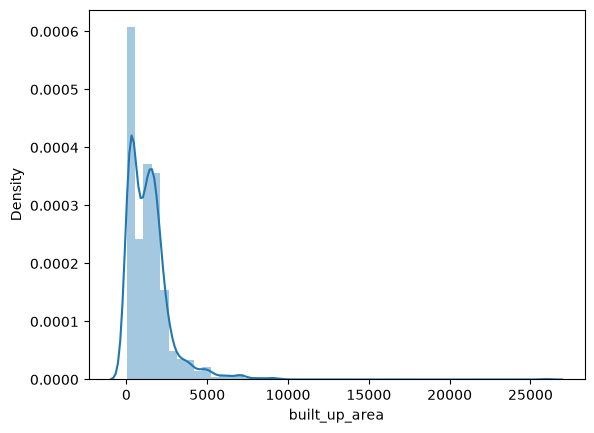

In [156]:
sns.distplot(df['built_up_area'])

<Axes: xlabel='built_up_area'>

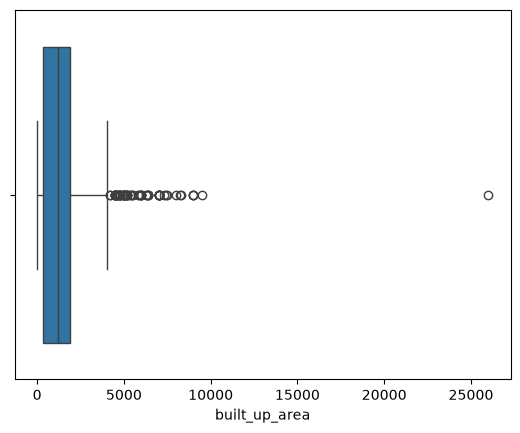

In [157]:
sns.boxplot(x=df['built_up_area'])

In [158]:
df[df['built_up_area'] > 10000]

,property_type,society,price,price_per_sqft,sector,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,Pooja Room,Study Room,Store Room,Servant Room,Others,furnishstatus,luxury_score,super_built_up_area,built_up_area,carpet_area
109,house,independent,1.45,557.0,ashok vihar phase i,26032.0,Plot area 26000(2415.48 sq.m.),4,4,2.0,2.0,East,Old,1,0,0,1,0,2,62,NaN,26000.0,NaN


### carpet area

/var/folders/b_/s74htpc90ps4hdvn1vgvtjgr0000gn/T/ipykernel_2070/3905767603.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['carpet_area'])


<Axes: xlabel='carpet_area', ylabel='Density'>

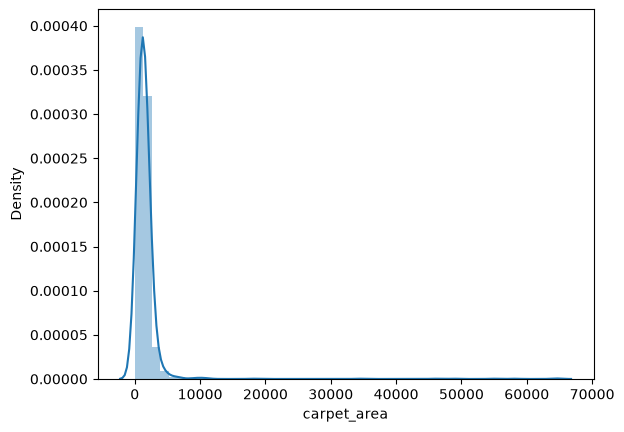

In [159]:
sns.distplot(df['carpet_area'])

<Axes: xlabel='carpet_area'>

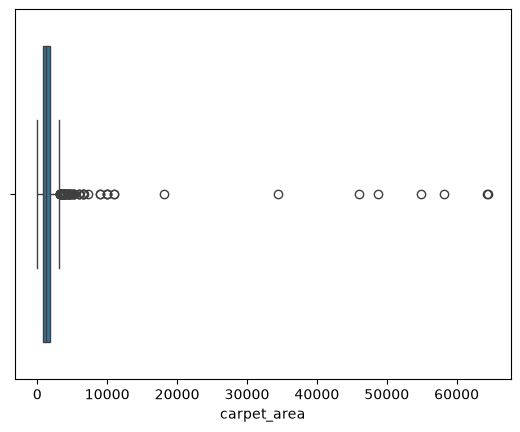

In [160]:
sns.boxplot(x=df['carpet_area'])

In [161]:
df[df['carpet_area'] > 10000]

,property_type,society,price,price_per_sqft,sector,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,Pooja Room,Study Room,Store Room,Servant Room,Others,furnishstatus,luxury_score,super_built_up_area,built_up_area,carpet_area
89,flat,rof ananda,0.210,NaN,sector 95,34426.23,Carpet area: 34401 (3195.96 sq.m.),1,1,1.0,13.0,North,Medium Aged,0,0,0,0,0,1,68,NaN,NaN,34401.0
267,house,independent,18.400,1859.0,dlf phase 1,98978.00,Plot area 502(419.74 sq.m.)Carpet area: 11000 ...,6,8,3.0,4.0,South,Medium Aged,1,0,1,1,0,2,60,NaN,NaN,11000.0
848,flat,m,13.200,NaN,sector 65,11000.00,Carpet area: 11000 (1021.93 sq.m.),4,4,3.0,13.0,North,Old,0,0,0,1,0,0,60,NaN,NaN,11000.0
1377,flat,rof ananda,0.330,NaN,sector 95,55000.00,Carpet area: 54917 (5101.96 sq.m.),2,2,1.0,13.0,South-West,Medium Aged,0,0,0,0,0,1,37,NaN,NaN,54917.0
1850,flat,godrej air,2.500,NaN,sector 85,18129.08,Carpet area: 18122 (1683.59 sq.m.),4,5,3.0,16.0,North-East,Under Construction,1,1,0,0,1,2,44,NaN,NaN,18122.0
1972,flat,rof ananda,0.375,NaN,sector 95,64655.17,Carpet area: 64529 (5994.94 sq.m.),2,2,2.0,10.0,East,New,0,1,0,0,0,1,15,NaN,NaN,64529.0
2149,flat,ramsons kshitij,0.245,NaN,sector 95,46226.42,Carpet area: 45966 (4270.38 sq.m.),2,2,1.0,10.0,North-West,Medium Aged,0,0,0,0,1,1,33,NaN,NaN,45966.0
2391,flat,pyramid elite,0.460,NaN,sector 86,58227.85,Carpet area: 58141 (5401.48 sq.m.),2,2,1.0,0.0,NaN,Under Construction,0,0,0,0,0,1,15,NaN,NaN,58141.0
2770,flat,signature the serenas,0.280,NaN,sohna road,49122.81,Carpet area: 48811 (4534.69 sq.m.),1,1,2.0,1.0,North-West,Medium Aged,0,1,0,0,0,1,37,NaN,NaN,48811.0
3679,flat,rof ananda,0.380,NaN,sector 95,65517.24,Carpet area: 64412 (5984.07 sq.m.),3,2,1.0,12.0,North,Medium Aged,0,0,0,0,0,1,51,NaN,NaN,64412.0


In [162]:
df.loc[2131,'carpet_area'] = 1812

In [163]:
df[df['carpet_area'] > 10000]

,property_type,society,price,price_per_sqft,sector,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,Pooja Room,Study Room,Store Room,Servant Room,Others,furnishstatus,luxury_score,super_built_up_area,built_up_area,carpet_area
89,flat,rof ananda,0.210,NaN,sector 95,34426.23,Carpet area: 34401 (3195.96 sq.m.),1,1,1.0,13.0,North,Medium Aged,0,0,0,0,0,1,68,NaN,NaN,34401.0
267,house,independent,18.400,1859.0,dlf phase 1,98978.00,Plot area 502(419.74 sq.m.)Carpet area: 11000 ...,6,8,3.0,4.0,South,Medium Aged,1,0,1,1,0,2,60,NaN,NaN,11000.0
848,flat,m,13.200,NaN,sector 65,11000.00,Carpet area: 11000 (1021.93 sq.m.),4,4,3.0,13.0,North,Old,0,0,0,1,0,0,60,NaN,NaN,11000.0
1377,flat,rof ananda,0.330,NaN,sector 95,55000.00,Carpet area: 54917 (5101.96 sq.m.),2,2,1.0,13.0,South-West,Medium Aged,0,0,0,0,0,1,37,NaN,NaN,54917.0
1850,flat,godrej air,2.500,NaN,sector 85,18129.08,Carpet area: 18122 (1683.59 sq.m.),4,5,3.0,16.0,North-East,Under Construction,1,1,0,0,1,2,44,NaN,NaN,18122.0
1972,flat,rof ananda,0.375,NaN,sector 95,64655.17,Carpet area: 64529 (5994.94 sq.m.),2,2,2.0,10.0,East,New,0,1,0,0,0,1,15,NaN,NaN,64529.0
2149,flat,ramsons kshitij,0.245,NaN,sector 95,46226.42,Carpet area: 45966 (4270.38 sq.m.),2,2,1.0,10.0,North-West,Medium Aged,0,0,0,0,1,1,33,NaN,NaN,45966.0
2391,flat,pyramid elite,0.460,NaN,sector 86,58227.85,Carpet area: 58141 (5401.48 sq.m.),2,2,1.0,0.0,NaN,Under Construction,0,0,0,0,0,1,15,NaN,NaN,58141.0
2770,flat,signature the serenas,0.280,NaN,sohna road,49122.81,Carpet area: 48811 (4534.69 sq.m.),1,1,2.0,1.0,North-West,Medium Aged,0,1,0,0,0,1,37,NaN,NaN,48811.0
3679,flat,rof ananda,0.380,NaN,sector 95,65517.24,Carpet area: 64412 (5984.07 sq.m.),3,2,1.0,12.0,North,Medium Aged,0,0,0,0,0,1,51,NaN,NaN,64412.0


In [164]:
df.head()

,property_type,society,price,price_per_sqft,sector,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,Pooja Room,Study Room,Store Room,Servant Room,Others,furnishstatus,luxury_score,super_built_up_area,built_up_area,carpet_area
0,flat,indiabulls centrum park,2.45,NaN,sector 103,2875.25,Super Built up area 2875(267.1 sq.m.),4,4,3.0,11.0,East,Medium Aged,1,1,1,1,0,0,38,2875.0,NaN,NaN
1,house,project mianwali colony,2.00,14815.0,mianwali colony,1350.00,Built Up area: 1350 (125.42 sq.m.),5,5,2.0,3.0,East,Undefined,0,0,0,0,0,0,0,NaN,1350.0,NaN
3,flat,rof ananda,0.38,NaN,sector 95,549.21,Carpet area: 549.17 (51.02 sq.m.),2,2,1.0,4.0,NaN,New,0,0,0,0,0,1,0,NaN,NaN,549.174178
4,flat,sare homes,0.68,NaN,sector 92,1298.21,Carpet area: 1298 (120.59 sq.m.),3,3,2.0,11.0,North-West,Medium Aged,1,0,0,0,0,1,100,NaN,NaN,1298.000000
5,flat,pyramid urban homes,0.60,NaN,sector 86,750.00,Carpet area: 750 (69.68 sq.m.),3,2,2.0,2.0,East,Under Construction,0,0,0,0,0,1,13,NaN,NaN,750.000000


/var/folders/b_/s74htpc90ps4hdvn1vgvtjgr0000gn/T/ipykernel_2070/3385064764.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['luxury_score'])


<Axes: xlabel='luxury_score', ylabel='Density'>

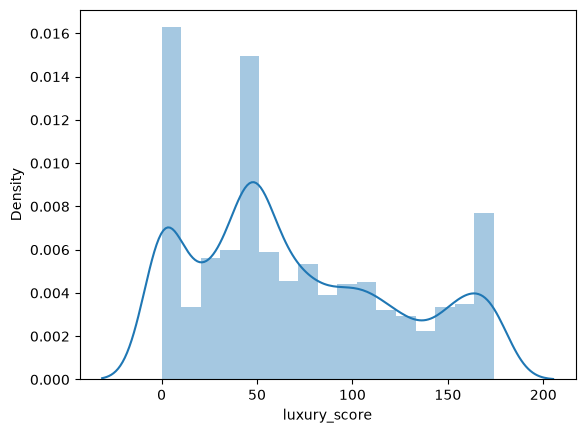

In [165]:
sns.distplot(df['luxury_score'])

<Axes: ylabel='luxury_score'>

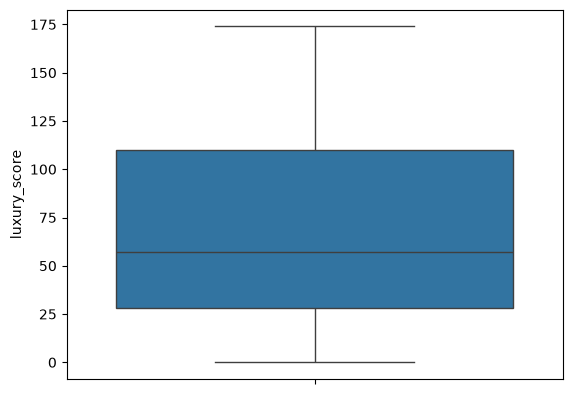

In [166]:
sns.boxplot(df['luxury_score'])

In [167]:
df.shape

(3681, 23)

In [168]:
df['price_per_sqft'] = round((df['price']*10000000)/df['area'])

In [169]:
df.head()

,property_type,society,price,price_per_sqft,sector,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,Pooja Room,Study Room,Store Room,Servant Room,Others,furnishstatus,luxury_score,super_built_up_area,built_up_area,carpet_area
0,flat,indiabulls centrum park,2.45,8521.0,sector 103,2875.25,Super Built up area 2875(267.1 sq.m.),4,4,3.0,11.0,East,Medium Aged,1,1,1,1,0,0,38,2875.0,NaN,NaN
1,house,project mianwali colony,2.00,14815.0,mianwali colony,1350.00,Built Up area: 1350 (125.42 sq.m.),5,5,2.0,3.0,East,Undefined,0,0,0,0,0,0,0,NaN,1350.0,NaN
3,flat,rof ananda,0.38,6919.0,sector 95,549.21,Carpet area: 549.17 (51.02 sq.m.),2,2,1.0,4.0,NaN,New,0,0,0,0,0,1,0,NaN,NaN,549.174178
4,flat,sare homes,0.68,5238.0,sector 92,1298.21,Carpet area: 1298 (120.59 sq.m.),3,3,2.0,11.0,North-West,Medium Aged,1,0,0,0,0,1,100,NaN,NaN,1298.000000
5,flat,pyramid urban homes,0.60,8000.0,sector 86,750.00,Carpet area: 750 (69.68 sq.m.),3,2,2.0,2.0,East,Under Construction,0,0,0,0,0,1,13,NaN,NaN,750.000000


/var/folders/b_/s74htpc90ps4hdvn1vgvtjgr0000gn/T/ipykernel_2070/2186227091.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['price_per_sqft'])


<Axes: xlabel='price_per_sqft', ylabel='Density'>

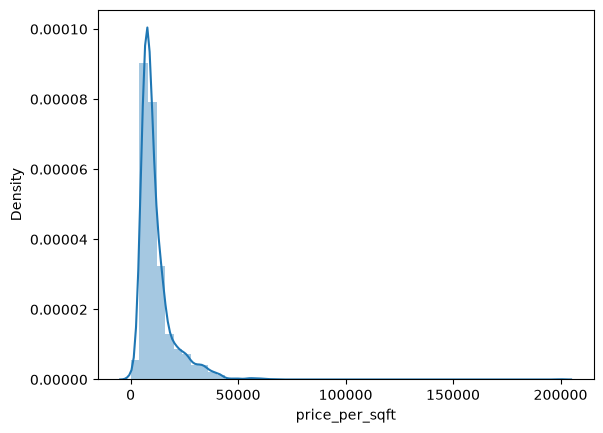

In [170]:
sns.distplot(df['price_per_sqft'])

<Axes: ylabel='price_per_sqft'>

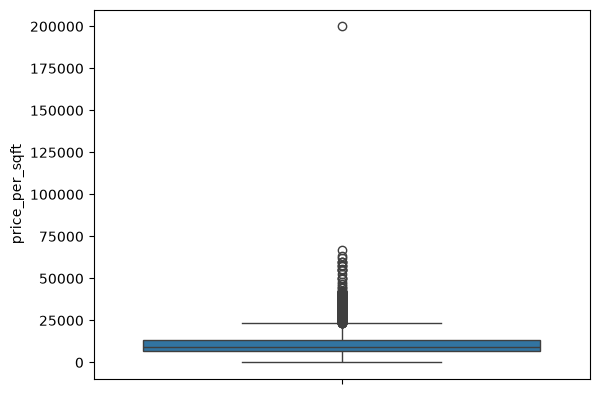

In [171]:
sns.boxplot(df['price_per_sqft'])

In [172]:
df[df['price_per_sqft'] > 42000]

,property_type,society,price,price_per_sqft,sector,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,Pooja Room,Study Room,Store Room,Servant Room,Others,furnishstatus,luxury_score,super_built_up_area,built_up_area,carpet_area
12,house,independent,0.30,60000.0,surat nagar phase 2,50.00,Plot area 50(4.65 sq.m.),6,3,3.0,3.0,South,Old,0,0,0,0,0,1,0,NaN,50.0,NaN
346,house,dlf city plots,26.00,57206.0,dlf phase 1,4545.00,Plot area 505(422.24 sq.m.),6,7,3.0,2.0,North-East,New,1,1,0,1,1,2,138,NaN,505.0,NaN
546,flat,unitech vistas,9.00,57507.0,sector 70,1565.03,Built Up area: 1565 (145.39 sq.m.),3,3,NaN,7.0,NaN,Undefined,0,0,0,0,0,1,0,NaN,1565.0,NaN
556,house,emaar mgf marbella,18.00,55556.0,sector 66,3240.00,Plot area 360(301.01 sq.m.),4,4,3.0,3.0,East,Old,1,1,0,1,0,2,75,NaN,360.0,NaN
897,flat,breez global hill view,2.60,46917.0,sohna road,554.17,Carpet area: 554.16 (51.48 sq.m.),2,2,2.0,6.0,NaN,New,0,0,0,0,0,1,42,NaN,NaN,554.125572
1239,house,shree krishna homes,0.48,50000.0,surat nagar 1,96.00,Plot area 80(7.43 sq.m.)Built Up area: 795 sq....,2,2,1.0,1.0,North-East,New,1,1,0,0,1,0,44,NaN,795.0,720.000000
1375,house,independent,19.00,42222.0,dlf phase 1,4500.00,Plot area 500(418.06 sq.m.),6,8,3.0,3.0,East,Old,1,1,1,1,0,2,103,NaN,500.0,NaN
1416,house,independent,1.10,55000.0,ravi nagar,200.00,Plot area 200(18.58 sq.m.),4,3,1.0,2.0,North-East,Very Old,0,0,0,0,0,1,0,NaN,200.0,NaN
1826,house,independent,5.00,44444.0,sector 55,1125.00,Plot area 125(104.52 sq.m.)Built Up area: 115 ...,9,9,3.0,5.0,East,New,0,0,0,0,1,2,44,NaN,115.0,100.000000
1845,house,project housing board colony,8.00,63492.0,sector 31,1260.00,Built Up area: 140 (117.06 sq.m.),2,1,0.0,1.0,NaN,Undefined,0,0,0,0,0,0,0,NaN,140.0,NaN


In [175]:
x = df[df['price_per_sqft'] <= 20000]
(x['area']/x['bedRoom']).quantile(0.05)

np.float64(242.2575)

In [176]:
df[(df['area']/df['bedRoom'])<250]

,property_type,society,price,price_per_sqft,sector,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,Pooja Room,Study Room,Store Room,Servant Room,Others,furnishstatus,luxury_score,super_built_up_area,built_up_area,carpet_area
11,house,jacobpura,0.525,14583.0,jacobpura,360.00,Plot area 360(33.45 sq.m.),4,4,2.0,3.0,East,Medium Aged,0,0,0,0,0,1,0,NaN,360.0,NaN
12,house,independent,0.300,60000.0,surat nagar phase 2,50.00,Plot area 50(4.65 sq.m.),6,3,3.0,3.0,South,Old,0,0,0,0,0,1,0,NaN,50.0,NaN
14,flat,laxmi pareena,0.300,6666.0,sector 99a,450.05,Carpet area: 450 (41.81 sq.m.),2,1,NaN,12.0,North,Undefined,0,0,0,0,0,0,0,NaN,NaN,450.000000
44,house,independent,0.750,20833.0,saraswati vihar,360.00,Plot area 40(33.45 sq.m.),7,4,3.0,4.0,NaN,Old,0,0,0,0,0,0,7,NaN,40.0,NaN
68,house,independent,0.450,10000.0,gandhi nagar,450.00,Built Up area: 50 (4.65 sq.m.),5,3,0.0,1.0,NaN,Undefined,0,0,0,0,0,0,0,NaN,50.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3801,house,not applicable,0.800,54795.0,laxman vihar,146.00,Plot area 146(13.56 sq.m.),5,4,3.0,3.0,NaN,Under Construction,0,0,0,0,0,1,0,NaN,146.0,NaN
3806,house,dlf city plots phase 3,1.600,29630.0,dlf phase 3,540.00,Plot area 540(50.17 sq.m.)Built Up area: 540 s...,8,5,3.0,4.0,East,Very Old,0,0,0,0,0,0,8,NaN,540.0,500.000000
3810,house,sushant lok 1 builder floors,1.650,30556.0,sushant lok phase 1,540.00,Plot area 60(50.17 sq.m.)Built Up area: 540 sq...,4,4,3.0,4.0,West,Old,0,0,0,0,1,2,49,NaN,540.0,500.000000
3826,house,naman residency,0.500,11111.0,laxman vihar,450.00,Plot area 450(41.81 sq.m.),2,2,2.0,2.0,West,New,1,1,0,1,1,0,14,NaN,450.0,NaN


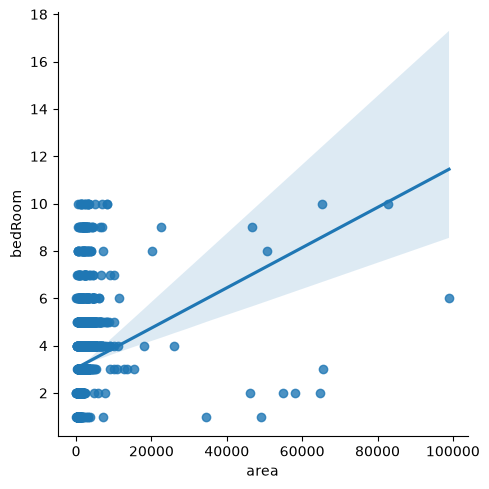

In [177]:
sns.lmplot(data=df,x='area',y='bedRoom')

In [178]:
df['area_room_ratio']=df['area']/df['bedRoom']

In [179]:
df[df['area_room_ratio']<250]['bedRoom'].value_counts()

bedRoom
2     54
3     39
4     36
5     35
6     26
9     20
8     14
7     11
10     9
1      1
Name: count, dtype: int64

In [180]:
df=df[df['area_room_ratio']>100]

In [181]:
outliers_df=df[(df['area_room_ratio']<250) & (df['bedRoom']>3)]

In [182]:
outliers_df['bedRoom']=round(outliers_df['bedRoom']/outliers_df['floorNum'])

/var/folders/b_/s74htpc90ps4hdvn1vgvtjgr0000gn/T/ipykernel_2070/3359844150.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  outliers_df['bedRoom']=round(outliers_df['bedRoom']/outliers_df['floorNum'])


In [183]:
df.update(outliers_df)

/opt/anaconda3/lib/python3.13/site-packages/pandas/core/dtypes/cast.py:377: RuntimeWarning: invalid value encountered in cast
  new_result = trans(result).astype(dtype)
/var/folders/b_/s74htpc90ps4hdvn1vgvtjgr0000gn/T/ipykernel_2070/3159295313.py:1: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[4. 5. 2. ... 3. 3. 2.]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df.update(outliers_df)


In [184]:
df['area_room_ratio']=df['area']/df['bedRoom']

In [188]:
df=df[~((df['area_room_ratio']<250) & (df['bedRoom']>4))]

In [189]:
df.to_csv('/Users/anshjj/Downloads/Campusx_Project/data/Cleaned/property_outlier_treated.csv',index=False)